In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, binom
import math
    

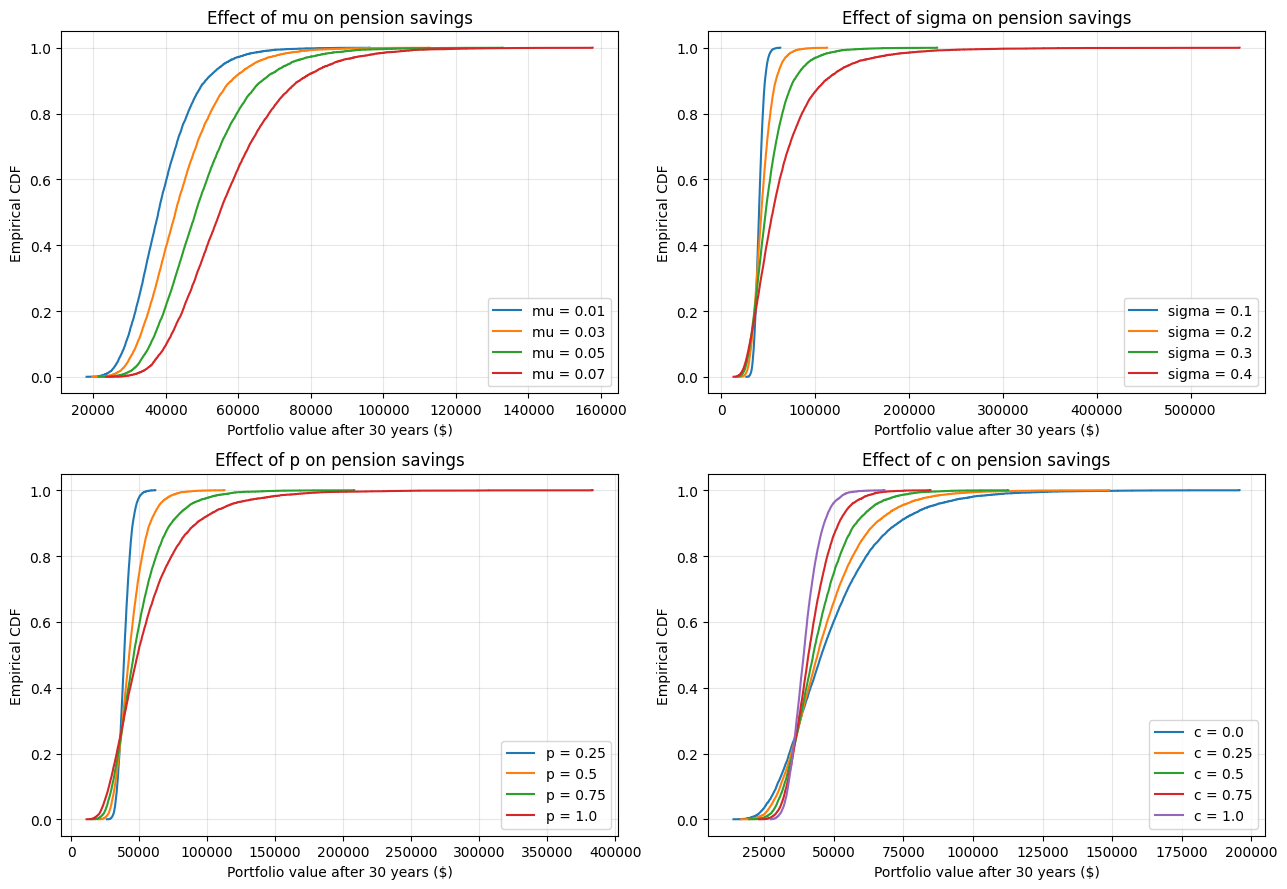

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(37)

r = 0.01
V_0 = 1000
n = 10000

def pension(mu, sigma, c, p, Z_k):
    V_list = [0]

    R_k = np.exp(mu + sigma * Z_k)

    for k in range(1, 31):
        w_k = p * (1 - c * (k - 1) / 30)

        V_k = (V_list[k-1] + V_0) * (
            w_k * R_k[k-1] + (1-w_k) * np.exp(r)
        )

        V_list.append(float(V_k))

    return V_list[-1]


mu_values = [0.01, 0.03, 0.05, 0.07]
sigma_values = [0.10, 0.20, 0.30, 0.40]
p_values = [0, 0.25, 0.50, 0.75, 1.00]
c_values = [0.00, 0.25, 0.50, 0.75, 1.00]

# Generate n simulations, each containing 30 annual returns
Z = np.random.normal(0, 1, (n, 30))

# Store results for each parameter value
mu_results = {}
sigma_results = {}
p_results = {}
c_results = {}

# Vary mu
for mu in mu_values:
    V_30 = np.array([
        pension(mu, 0.2, 0.5, 0.5, z)
        for z in Z
    ])
    mu_results[mu] = V_30

# Vary sigma
for sigma in sigma_values:
    V_30 = np.array([
        pension(0.03, sigma, 0.5, 0.5, z)
        for z in Z
    ])
    sigma_results[sigma] = V_30

# Vary p
for p in p_values:
    V_30 = np.array([
        pension(0.03, 0.2, 0.5, p, z)
        for z in Z
    ])
    p_results[p] = V_30

# Vary c
for c in c_values:
    V_30 = np.array([
        pension(0.03, 0.2, c, 0.5, z)
        for z in Z
    ])
    c_results[c] = V_30





results = {
    "mu": mu_results,
    "sigma": sigma_results,
    "p": p_results,
    "c": c_results
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (parameter, distributions) in zip(axes.flat, results.items()):
    for value, V_30 in distributions.items():
        V_sorted = np.sort(V_30)
        F_n = np.arange(1, len(V_30)+1) / len(V_30)

        ax.step(V_sorted, F_n, where="post",
                label=f"{parameter} = {value}")

    ax.set_title(f"Effect of {parameter} on pension savings")
    ax.set_xlabel("Portfolio value after 30 years ($)")
    ax.set_ylabel("Empirical CDF")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [17]:
mu = 0.03
sigma = 0.2

p_values = [0, 0.25, 0.50, 0.75, 1.00]
c_values = [0.00, 0.25, 0.50, 0.75, 1.00]

Z = np.random.normal(0, 1, (n, 30))

V_30_b = {}
for p in p_values:
    for c in c_values:
        V_30_b[(p, c)] = np.array([
            pension(mu, sigma, c, p, z)
            for z in Z
        ])

results_b = []

for (p, c), V_30 in V_30_b.items():
    mean = np.mean(V_30)
    quantile = np.quantile(V_30, 0.01)

    results_b.append([p, c, mean, quantile])

results_b = np.array(results_b)
optimal_index = np.argmax(results_b[:, 3])

optimal_p = results_b[optimal_index, 0]
optimal_c = results_b[optimal_index, 1]

print("Optimal p:", optimal_p)
print("Optimal c:", optimal_c)
print("Mean E[V30]:", results_b[optimal_index, 2])
print("1% quantile:", results_b[optimal_index, 3])

Optimal p: 0.0
Optimal c: 0.0
Mean E[V30]: 35161.10170990865
1% quantile: 35161.10170990865


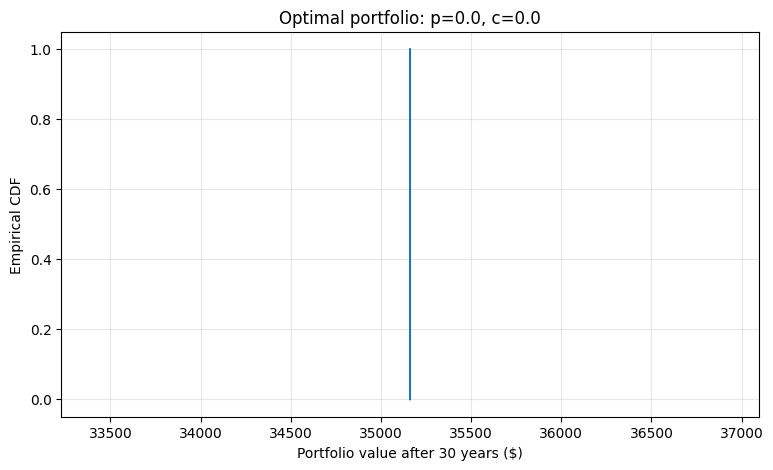

In [18]:
V_optimal = V_30_b[(optimal_p, optimal_c)]

V_sorted = np.sort(V_optimal)
F_n = np.arange(1, n+1) / n

plt.figure(figsize=(9, 5))
plt.step(V_sorted, F_n, where="post")

plt.xlabel("Portfolio value after 30 years ($)")
plt.ylabel("Empirical CDF")
plt.title(f"Optimal portfolio: p={optimal_p}, c={optimal_c}")
plt.grid(alpha=0.3)
plt.show()